# 03 · Patterns in negative prices

When do negative prices happen, and how does that change with the season, the year and the type of day? This notebook describes the prediction target; it doesn't model it.

- **Input:** `data/processed/panel.parquet` (built by `make data`)
- **Target:** `is_neg` = 1 if the half-hour mean price is below $0 (see `references/data_dictionary.md`)
- **Excluded:** half-hours flagged `admin_price` (13–24 Jun 2022). Prices on those days were set administratively, not by the market
- **Time:** NEM time (UTC+10 all year, no daylight saving); `HH_END` marks the **end** of each half-hour

In [10]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from negprice.config import FIGURES_DIR, PROCESSED_DATA_DIR, REGIONS

cols = ["REGIONID", "HH_END", "DAY", "rrp_mean", "rrp_min", "n_neg_5min", "is_neg", "admin_price"]
panel = pd.read_parquet(PROCESSED_DATA_DIR / "panel.parquet", columns=cols)
panel = panel[~panel["admin_price"]].copy()

start = panel["HH_END"] - pd.Timedelta("30min")
panel["slot"] = start.dt.hour * 2 + start.dt.minute // 30  # 0 = 00:00–00:30, ..., 47 = 23:30–24:00
panel["month"] = panel["DAY"].dt.month

MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
print(f"{len(panel):,} half-hours")
print(panel.groupby("REGIONID")["is_neg"].mean().loc[REGIONS].round(3))

261,216 half-hours
REGIONID
SA1     0.253
VIC1    0.214
NSW1    0.067
Name: is_neg, dtype: float64


## 1. Time of day × month

The share of negative half-hours depends on the time of day, but that profile may itself change through the year (sunrise and sunset times, solar strength, wind, heating and cooling demand). If it does, time of day and season interact, and the model needs both.

**How to read it:** one heatmap per region, one shared colour scale. Each cell is the share of half-hours with `is_neg = 1` for that month and half-hour, pooled over all years. Each cell spans its actual interval: the cell between 12:00 and 12:30 is the half-hour ending 12:30.

**Sample size:** every calendar month has exactly five years of data (Oct–Dec from 2021–2025, Jan–Sep from 2022–2026), so the upward trend over the years doesn't favour particular months. Each cell holds 138–155 days, so the sampling noise is at most about ±4 percentage points.

days per cell: 138 to 155


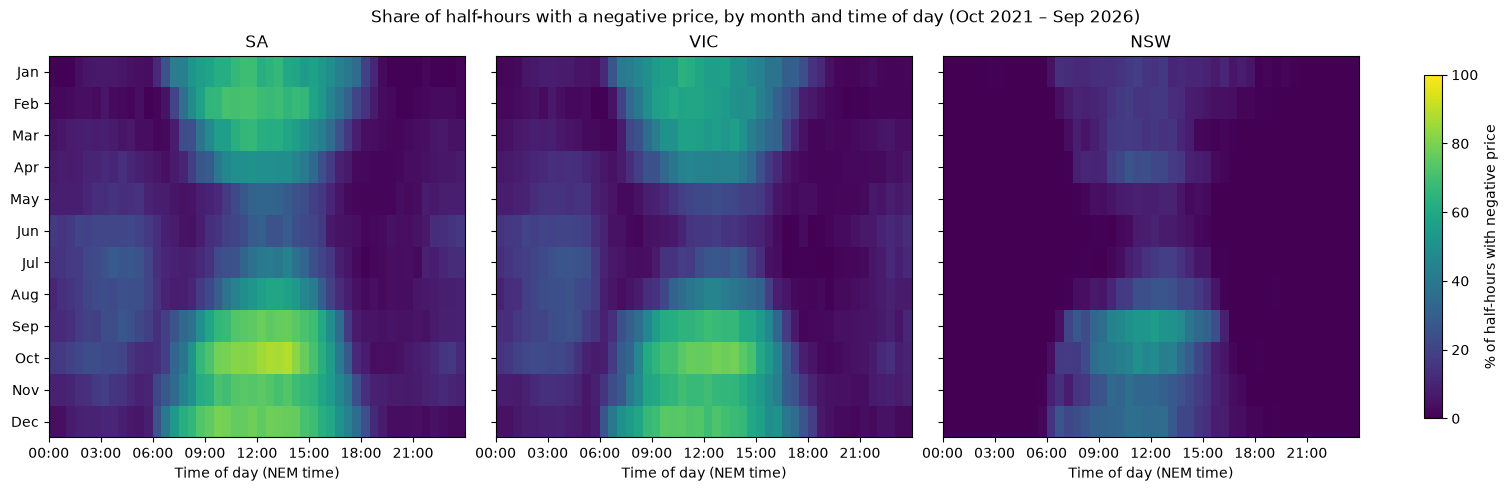

In [12]:
share = panel.pivot_table(index=["REGIONID", "month"], columns="slot", values="is_neg", aggfunc="mean") * 100
n_days = panel.groupby(["REGIONID", "month", "slot"]).size()
print("days per cell:", n_days.min(), "to", n_days.max())

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True, layout="constrained")
x_edges = np.arange(49) / 2  # hours, 00:00 ... 24:00
y_edges = np.arange(13) + 0.5
for ax, region in zip(axes, REGIONS):
    mesh = ax.pcolormesh(x_edges, y_edges, share.loc[region].values, cmap="viridis", vmin=0, vmax=100)
    ax.set_title(region.removesuffix("1"))
    ax.set_xticks(range(0, 24, 3), [f"{h:02d}:00" for h in range(0, 24, 3)])
    ax.set_xlabel("Time of day (NEM time)")
axes[0].set_yticks(range(1, 13), MONTHS)
axes[0].invert_yaxis()
fig.colorbar(mesh, ax=axes, label="% of half-hours with negative price", shrink=0.9)
fig.suptitle("Share of half-hours with a negative price, by month and time of day (Oct 2021 – Sep 2026)")
fig_heatmap = fig


In [13]:
# Summary numbers behind the findings below
midday = list(range(22, 28))  # 11:00–14:00
night = list(range(0, 12))    # 00:00–06:00
seasons = {"Dec–Feb": [12, 1, 2], "Mar–May": [3, 4, 5], "Jun–Aug": [6, 7, 8], "Sep–Nov": [9, 10, 11]}

rows = []
for region in REGIONS:
    s = share.loc[region]
    peak_month, peak_slot = s.stack().idxmax()
    row = {"region": region, "peak %": s.stack().max(), "peak month": MONTHS[peak_month - 1],
           "peak starts": f"{peak_slot // 2:02d}:{30 * (peak_slot % 2):02d}"}
    for name, months in seasons.items():
        row[f"midday {name}"] = s.loc[months, midday].values.mean()
        row[f"night {name}"] = s.loc[months, night].values.mean()
    rows.append(row)
pd.DataFrame(rows).set_index("region").round(1).T

region,SA1,VIC1,NSW1
peak %,88.4,78.7,55.3
peak month,Oct,Oct,Sep
peak starts,13:30,12:30,12:00
midday Dec–Feb,70.2,61.0,20.1
night Dec–Feb,4.9,5.2,0.1
midday Mar–May,47.6,40.5,14.5
night Mar–May,9.0,9.3,0.0
midday Jun–Aug,40.4,27.5,15.6
night Jun–Aug,20.3,19.4,0.0
midday Sep–Nov,78.1,70.4,42.0


**Result**

- **Midday solar block, strongest in spring.** The peak is in September–October, not in summer: SA 88% (October, 13:30–14:00), VIC 79% (October, 12:30–13:00), NSW 55% (September, 12:00–12:30). Between 11:00 and 14:00, spring (Sep–Nov) averages SA 78%, VIC 70%, NSW 42%, against SA 40%, VIC 28%, NSW 16% in winter (Jun–Aug). A likely reason: spring combines strong sun with mild temperatures, so demand is low (little heating or air conditioning).
- **The block's edges follow the sun.** It starts around 06:00–06:30 in Dec–Jan but not before about 08:30 in Apr–Jun, and ends around 18:00 in summer and 16:00 in winter. A fixed "hour of day" means a different position relative to sunrise in each month.
- **A second, overnight block in SA and VIC from winter to spring.** Between 00:00 and 06:00, about 20% of half-hours are negative in Jun–Aug and about 16% in Sep–Nov, against about 5% in Dec–Feb. This isn't solar; it lines up with the windy season (late winter and spring). NSW has almost no negative prices at night (0.0% in winter).
- **NSW is a weaker version of the same midday pattern**, with no overnight block.

**Implications for the model:** time of day and season interact, so the model needs both (and a tree model can learn the interaction). A sun-position feature (e.g. solar elevation) would capture the moving edges more directly than hour + month. The overnight winter block points to AEMO's wind forecast (`pd_ss_wind_uigf`) as a relevant input for SA and VIC.

## 2. Trend over the years

The base rate the model learns from older years may not hold in the years it is tested on. If the share of negative half-hours drifts, the backtest has to respect time order, and a single base rate over the full window is misleading.

**Years run October to September** (labelled by the year they end in, e.g. 2023 = Oct 2022 – Sep 2023). The window then splits into five full years, each with every season once. Calendar years don't work here: 2021 holds only Oct–Dec (the high season) and 2026 only Jan–Sep.

In [14]:
panel["year"] = panel["DAY"].dt.year + (panel["DAY"].dt.month >= 10)  # Oct–Sep year, labelled by its end
by_year = panel.pivot_table(index="year", columns="REGIONID", values="is_neg", aggfunc="mean")[REGIONS] * 100
by_year.round(1)

REGIONID,SA1,VIC1,NSW1
year,,,
2022,18.0,13.9,2.1
2023,26.1,22.5,5.2
2024,25.1,21.6,7.1
2025,28.2,22.6,10.2
2026,29.0,25.9,8.9


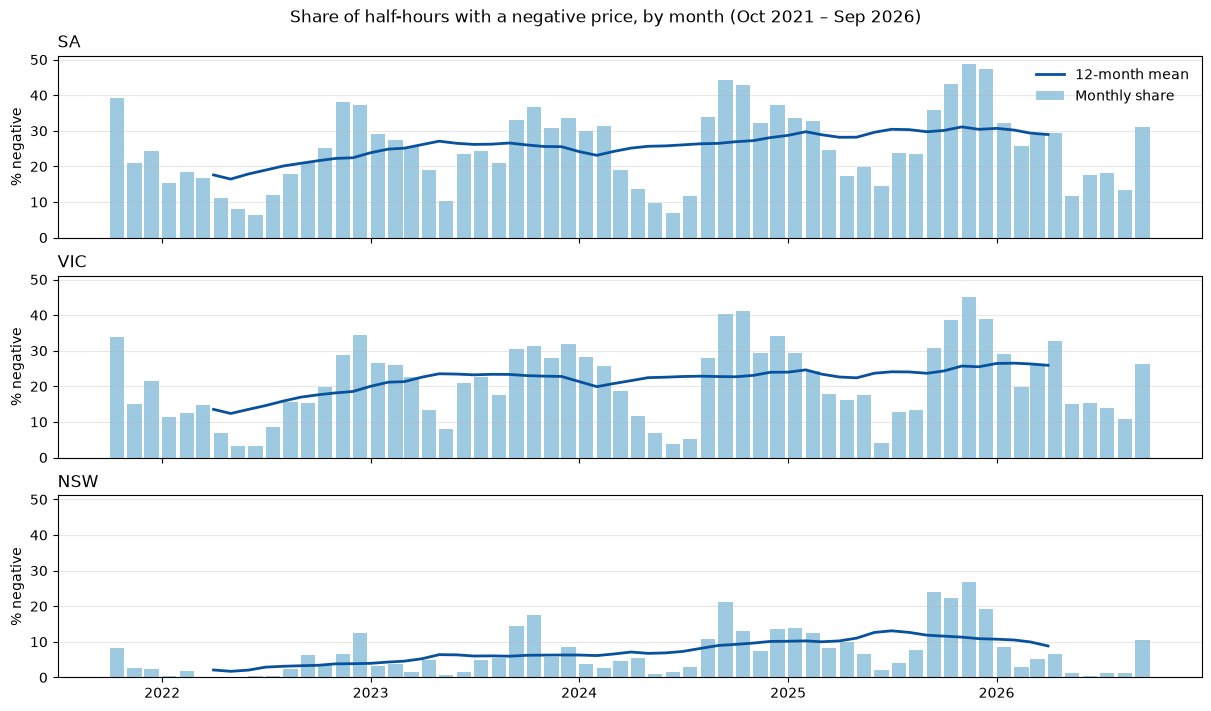

In [15]:
monthly = (
    panel.assign(month_start=panel["DAY"].dt.to_period("M").dt.to_timestamp())
    .pivot_table(index="month_start", columns="REGIONID", values="is_neg", aggfunc="mean")[REGIONS] * 100
)
rolling = monthly.rolling(12, center=True).mean()  # 12-month mean: removes the seasonal cycle

fig, axes = plt.subplots(3, 1, figsize=(12, 7), sharex=True, sharey=True, layout="constrained")
for ax, region in zip(axes, REGIONS):
    ax.bar(monthly.index, monthly[region], width=25, align="edge", color="#9ecae1", label="Monthly share")
    ax.plot(rolling.index, rolling[region], color="#08519c", lw=2, label="12-month mean")
    ax.set_title(region.removesuffix("1"), loc="left")
    ax.set_ylabel("% negative")
    ax.grid(axis="y", alpha=0.3)
axes[0].legend(loc="upper right", frameon=False)
fig.suptitle("Share of half-hours with a negative price, by month (Oct 2021 – Sep 2026)");
fig_trend = fig

In [19]:
rolling

REGIONID,SA1,VIC1,NSW1
month_start,,,
2021-10-01,NaN,NaN,NaN
2021-11-01,NaN,NaN,NaN
2021-12-01,NaN,NaN,NaN
2022-01-01,NaN,NaN,NaN
2022-02-01,NaN,NaN,NaN
2022-03-01,NaN,NaN,NaN
2022-04-01,17.608469,13.524408,2.082218
2022-05-01,16.443595,12.365134,1.706994
2022-06-01,17.878780,13.510967,2.042642


In [16]:
# Same quarters, 2025 vs 2026 (2026 data ends in September)
same_q = panel.assign(quarter=panel["DAY"].dt.quarter, cal_year=panel["DAY"].dt.year)
same_q = same_q[same_q["cal_year"].isin([2025, 2026]) & (same_q["quarter"] <= 3)]
(same_q.pivot_table(index=["quarter", "cal_year"], columns="REGIONID", values="is_neg", aggfunc="mean")[REGIONS]
 * 100).round(1)


REGIONID           SA1  VIC1  NSW1
quarter cal_year                  
1       2025      30.2  23.9  11.5
        2026      29.1  25.0   5.6
2       2025      17.3  12.7   6.2
        2026      19.5  20.9   2.7
3       2025      27.7  18.9  11.8
        2026      20.7  16.8   4.3

**Result**

| Oct–Sep year | SA | VIC | NSW |
|---|---|---|---|
| 2022 | 18.0% | 13.9% | 2.1% |
| 2023 | 26.1% | 22.5% | 5.2% |
| 2024 | 25.1% | 21.6% | 7.1% |
| 2025 | 28.2% | 22.6% | 10.2% |
| 2026 | 29.0% | 25.9% | 8.9% |

- **Rising, but not smoothly.** The big step is between the first two years. Oct 2021 – Sep 2022 includes the 2022 energy crisis (very high gas and coal prices), which kept prices up. After that, SA and VIC rise by about 1 point a year. NSW rises fastest in relative terms (about 5× from 2022 to 2025) but falls in the last year.
- **NSW dropped in 2026.** Each quarter of 2026 had about half the share of the same quarter of 2025 (Q1 5.6% vs 11.5%, Q2 2.7% vs 6.2%, Q3 4.3% vs 11.8%). SA and VIC are mixed: VIC's Q2 was higher (20.9% vs 12.7%), SA's Q3 lower (20.7% vs 27.7%). The NSW drop fits with AEMO's growing over-forecast of negative prices in NSW in 2026 (notebook 01). Possible causes (not checked): more grid-scale batteries charging at midday, or weather.
- **The seasonal swing is larger than the trend.** Within any year, the monthly share ranges from under 10% to over 40% in SA; the 12-month mean moves by a few points a year.

**Implications for the model:** the base rate drifts, so the backtest must be walk-forward (train on the past, test on the following period), never a random split. The most recent year doesn't simply continue the trend, so a model can't rely on "more negatives every year"; inputs that explain the level directly (AEMO's price and rooftop PV forecasts) matter more than a time trend.

## 3. The "46% in SA" figure

**Why:** a figure of 46% negative half-hours in SA is often quoted. Over the full window the share is 25%, so the figure must refer to a specific period. Check before quoting it.

In [17]:
quarterly = (
    panel.assign(quarter=panel["DAY"].dt.to_period("Q"))
    .pivot_table(index="quarter", columns="REGIONID", values="is_neg", aggfunc="mean")[REGIONS] * 100
)
any_5min = (
    panel.assign(quarter=panel["DAY"].dt.to_period("Q"), any_neg=panel["rrp_min"] < 0)
    .pivot_table(index="quarter", columns="REGIONID", values="any_neg", aggfunc="mean")[REGIONS] * 100
)
print("Half-hour mean < 0, by quarter:")
print(quarterly.round(1))
print("\nSA, Q4 2025: half-hour mean < 0 =", round(quarterly.loc["2025Q4", "SA1"], 1),
      "| any 5-min interval < 0 =", round(any_5min.loc["2025Q4", "SA1"], 1))

Half-hour mean < 0, by quarter:
REGIONID   SA1  VIC1  NSW1
quarter                   
2021Q4    28.2  23.6   4.4
2022Q1    16.8  13.0   0.7
2022Q2     8.9   4.6   0.1
2022Q3    16.8  13.2   3.0
2022Q4    33.5  27.7   7.6
2023Q1    27.3  25.0   2.8
2023Q2    17.5  14.0   2.3
2023Q3    26.0  23.4   8.1
2023Q4    33.8  30.3  10.7
2024Q1    26.7  24.2   3.6
2024Q2    10.1   7.4   2.6
2024Q3    29.8  24.3  11.5
2024Q4    37.5  35.0  11.4
2025Q1    30.2  23.9  11.5
2025Q2    17.3  12.7   6.2
2025Q3    27.7  18.9  11.8
2025Q4    46.4  40.7  22.7
2026Q1    29.1  25.0   5.6
2026Q2    19.5  20.9   2.7
2026Q3    20.7  16.8   4.3

SA, Q4 2025: half-hour mean < 0 = 46.4 | any 5-min interval < 0 = 50.8


**Result:** the figure is correct for **SA in Oct–Dec 2025**: 46.4% of half-hours had a negative mean price (50.8% had at least one negative 5-min interval). It is the highest quarter in the window; the next highest is Q4 2024 at 37.5%. Quote it with its period, next to the full-window rate (25%).

In [18]:
# Save the figures for the README and reports (notebooks are committed without outputs)
fig_heatmap.savefig(FIGURES_DIR / "negative_share_month_time_of_day.png", dpi=150, bbox_inches="tight")
fig_trend.savefig(FIGURES_DIR / "negative_share_by_month.png", dpi=150, bbox_inches="tight")
